# Multi-scale cell embeddings and niche discovery

SIGMMA embeds every cell at three spatial scales — **micro** (cell neighbourhood),
**meso** (micro-environment) and **macro** (niche) — by passing a hierarchical cell
graph through the spatial encoder that was aligned with H&E during training.

In this tutorial we:

1. load a trained SIGMMA checkpoint,
2. run one Xenium section (HEST-1k lung adenocarcinoma, `TENX118`) through the model,
3. collect per-cell embeddings at each scale into AnnData,
4. cluster each scale and compare the resulting domains in space,
5. trace how clusters merge or split from micro to macro.

**Requirements:** a GPU, the `sigmma[analysis]` extra, the UNI2-h weights and a SIGMMA
checkpoint (see {doc}`../installation`).

## Paths

Edit these to point at your copies of the data and checkpoints.

In [1]:
from pathlib import Path

DATA_DIR = Path("/lustre/scratch126/cellgen/lotfollahi/projects/sigmma/data/public_xenium/hest_1k_lung")
SAMPLE_NAME = "TENX118"
CKPT = Path("/lustre/scratch126/cellgen/lotfollahi/dj16/projects/sigmma_outputs/checkpoints/"
            "sigmma_dense_attnpool_gex_svg_a01/36852/checkpoint-step2000.pth")
UNI_DIR = Path("/nfs/team361/dj16/projects/SIGMMA/assets/ckpts/uni_h/")

sample_dir = DATA_DIR / SAMPLE_NAME
image_file = sample_dir / "hematoxylin_eosin.zarr"                       # H&E, (3, H, W) uint8, 0.5 µm/px
index_file = sample_dir / "index_mask_HAE_stride_256_tile_256.zarr"      # tissue tiles
spatial_file = sample_dir / "spatial_data_processed.h5"                  # AnnData with NEMO cell embeddings

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio
import torch
from torch.utils.data import DataLoader, SequentialSampler
from ml_collections.config_dict import ConfigDict

from sigmma.utils import load_model
from sigmma.datasets import SpatialPatchDataset, multimodal_collate
from sigmma.misc import (
    extract_graphs,
    extract_cell_embeddings_and_coordinates,
    integrate_into_single_anndata,
    add_graph_edge_to_adata,
    remove_NaN_cells,
)

plt.rcParams["figure.dpi"] = 80
pio.renderers.default = "notebook_connected"
device = torch.device("cuda")

## Load the model

The configuration must match the architecture of the checkpoint. This checkpoint uses
the UNI2-h image encoder with a single LoRA adapter and an attention-pooling head.

In [3]:
config = ConfigDict({
    "model": {
        "name": "sigmma",
        "checkpoint_path": str(CKPT),
        "pretrained_image_encoder": "UNI",
        "pretrained_image_encoder_ckpt_path": str(UNI_DIR),
        "image_encoder_input_dim": 1536,
        "image_encoder_output_dim": 512,
        "spatial_encoder_input_dim": 384,
        "spatial_encoder_output_dim": 512,
        "num_resolutions": 3,
        "contrastive_temperature": 0.07,
        "gumbel_temperature": 0.5,
        "edge_threshold": 0.5,
        "candidate_top_k": 8,
        "candidate_sim_threshold": 0.5,
        "dropout": 0.1,
        "activation": "leaky_relu",
        "aggregate": "attn_pool",
        "num_graph_layers": 2,
        "image_mlp_hidden_dim": 2048,
        "image_attn_pool_heads": 8,
        "lora": {
            "enabled": True, "r": 16, "alpha": 32, "dropout": 0.05,
            "target_modules": ["qkv", "proj"], "bias": "none", "per_scale": False,
        },
    },
    "test": {"batch_size": 1},
})

model = load_model(
    config,
    pretrained_image_encoder=config.model.pretrained_image_encoder,
    pretrained_ckpt_path=config.model.checkpoint_path,
    train=False,
)
model.to(device).eval();

sigmma parameters: trainable=60,718,019 / total=742,112,195 (8.18%)


Checkpoint DDP: False, Model DDP: False
Direct load (matching DDP status)
Loaded checkpoint from /lustre/scratch126/cellgen/lotfollahi/dj16/projects/sigmma_outputs/checkpoints/sigmma_dense_attnpool_gex_svg_a01/36852/checkpoint-step2000.pth at step 2000


## Load one section

`SpatialPatchDataset` tiles the H&E image into 256 × 256 px fields of view (FOVs) and,
for each FOV, builds the cell graph from the Xenium cells that fall inside it, with
NEMO cell embeddings as node features. `tissue_filtering_threshold=0` keeps every tile
so that all cells are embedded.

In [4]:
dataset = SpatialPatchDataset(
    image_file=image_file,
    spatial_file=spatial_file,
    indices_file=index_file,
    num_resolutions=3,
    tissue_filtering_threshold=0,
    type_pretrained_cell_embedding="nemo",
)
dataloader = DataLoader(
    dataset,
    batch_size=128,
    sampler=SequentialSampler(dataset),
    num_workers=4,
    collate_fn=multimodal_collate,
)
print(f"{len(dataset):,} FOVs")

1,191 FOVs


## Extract per-cell embeddings at three scales

`extract_graphs` runs the model over all FOVs and returns, for each scale, the cell
graphs with the learned node features. `extract_cell_embeddings_and_coordinates`
flattens them into `(cell_id, embedding, coordinate)` arrays.

In [5]:
graphs, _ = extract_graphs(dataloader, model, config, device, multi_scale=True)
rename = {"scale_0": "micro", "scale_1": "meso", "scale_2": "macro"}
graphs = {rename.get(k, k): v for k, v in graphs.items()}

SCALES = ("micro", "meso", "macro")
per_scale = {}
for scale in SCALES:
    cid, feat, coord = extract_cell_embeddings_and_coordinates(graphs[scale])
    per_scale[scale] = {"cell_id": cid, "feat": feat, "coord": coord}
    print(f"{scale:>5}: {feat.shape[0]:,} cells x {feat.shape[1]}-d")

micro: 145,493 cells x 512-d
 meso: 145,493 cells x 512-d


macro: 145,493 cells x 512-d


## Build one AnnData per scale

Each scale's embeddings are written to `obsm["sigmma_latent"]` of a copy of the
section's AnnData. The SIGMMA graph edges are stored as `obsp["sigmma_connectivities"]`,
and cells outside every FOV (no embedding) are dropped.

In [6]:
adata_in = sc.read_h5ad(spatial_file)

adatas = {}
for scale in SCALES:
    a = integrate_into_single_anndata(
        adata_in, per_scale[scale]["cell_id"], per_scale[scale]["feat"], key="sigmma_latent",
    )
    a = add_graph_edge_to_adata(a, graphs[scale])
    a = remove_NaN_cells(a, key="sigmma_latent")
    adatas[scale] = a
adatas["macro"]

Before: 146366 cells


After: 145493 cells
-----


Before: 146366 cells


After: 145493 cells
-----


Before: 146366 cells


After: 145493 cells
-----


AnnData object with n_obs × n_vars = 145493 × 372
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'run_name', 'region_name', 'section_name', 'n_genes', 'cell_id'
    var: 'ensembl_id', 'n_cells'
    uns: 'assay', 'batch', 'dataset_id', 'spatial_neighbors', 'species', 'tissue'
    obsm: 'nemo_latent', 'nemo_neighborhood_latent', 'spatial', 'sigmma_latent'
    obsp: 'spatial_connectivities', 'spatial_distances', 'sigmma_connectivities'

## Cluster each scale

Leiden clustering on `sigmma_latent` gives scale-specific domains. Small receptive
fields (micro) separate cell states; large ones (macro) group cells into tissue niches.

In [7]:
def cluster(adata, resolution=0.5, n_neighbors=15, seed=0):
    sc.pp.neighbors(adata, use_rep="sigmma_latent", n_neighbors=n_neighbors, key_added="sigmma")
    sc.tl.leiden(adata, resolution=resolution, neighbors_key="sigmma",
                 key_added="sigmma_leiden", random_state=seed)
    sc.tl.umap(adata, neighbors_key="sigmma")
    return adata

for scale in SCALES:
    cluster(adatas[scale])
    print(f"{scale:>5}: {adatas[scale].obs['sigmma_leiden'].nunique()} clusters")

micro: 33 clusters


 meso: 14 clusters


macro: 11 clusters


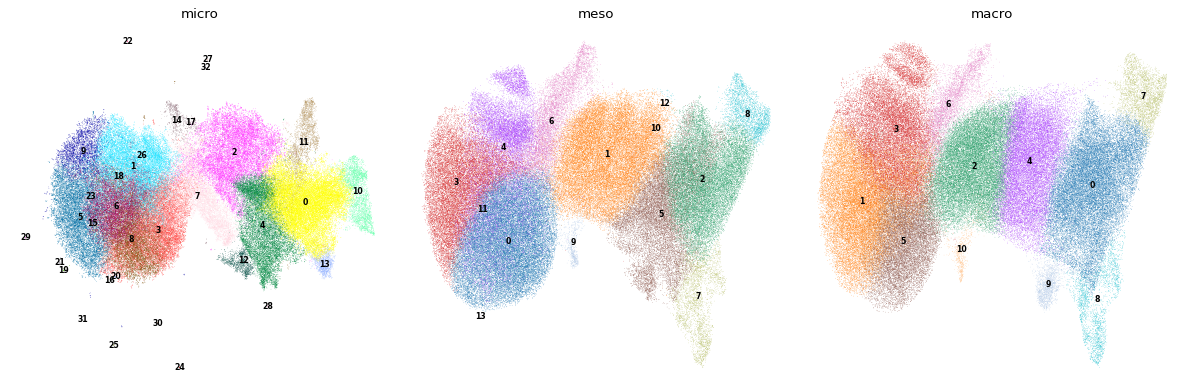

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, scale in zip(axes, SCALES):
    sc.pl.umap(adatas[scale], color="sigmma_leiden", ax=ax, show=False, frameon=False,
               title=scale, legend_loc="on data", legend_fontsize=7)
plt.tight_layout(); plt.show()

## Clusters in tissue space

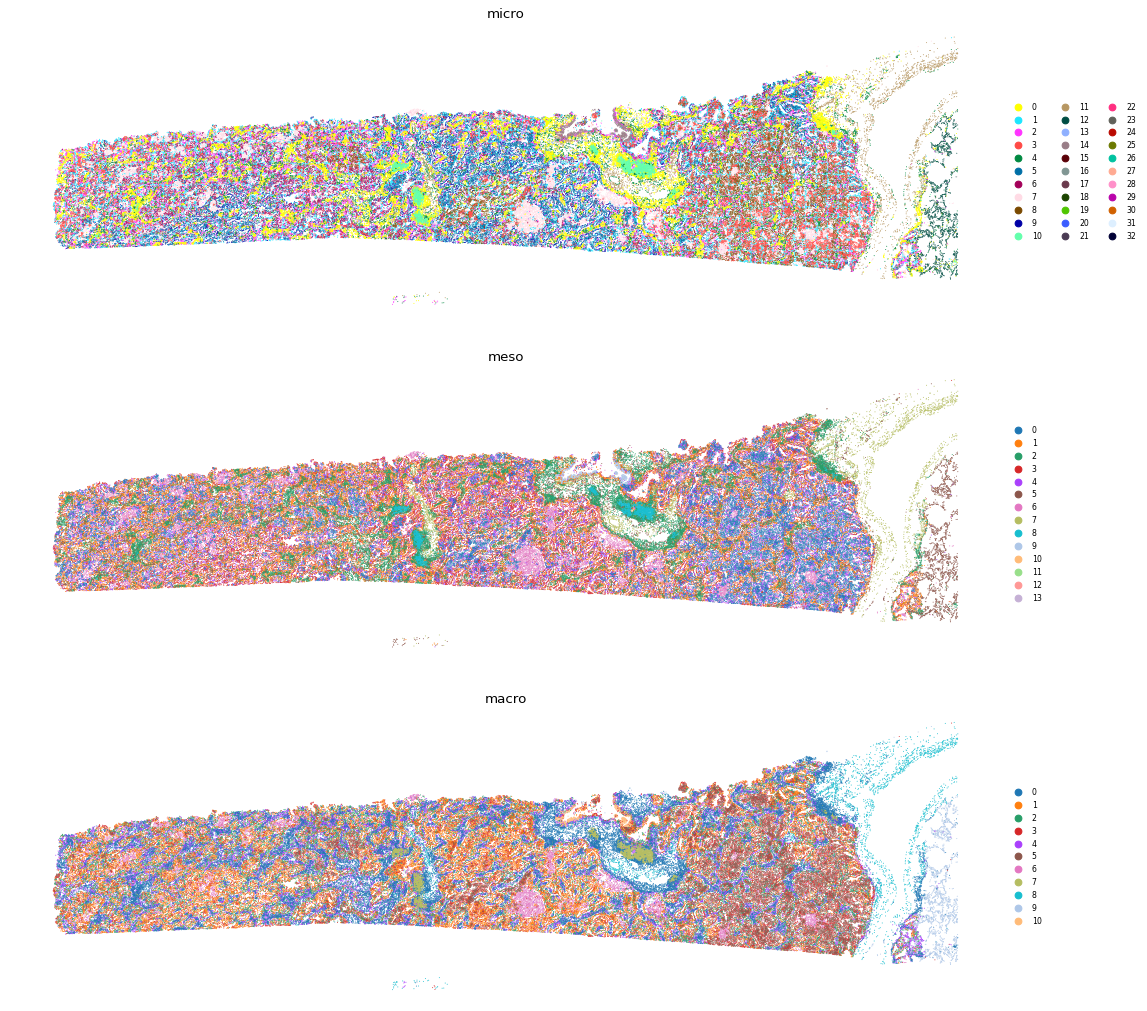

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(14, 13))
for ax, scale in zip(axes, SCALES):
    sc.pl.embedding(adatas[scale], basis="spatial", color="sigmma_leiden", ax=ax, show=False,
                    frameon=False, s=3, title=scale, legend_loc="right margin", legend_fontsize=7)
    ax.set_aspect("equal"); ax.invert_yaxis()
    for c in ax.collections:
        c.set_rasterized(True)
plt.tight_layout(); plt.show()

## How clusters change across scales

Each cell is assigned one cluster per scale. The Sankey diagram shows how micro
clusters merge into meso and macro clusters; link width is the number of cells.

In [10]:
shared = None
for scale in SCALES:
    s = adatas[scale].obs[["sigmma_leiden"]].rename(columns={"sigmma_leiden": scale})
    shared = s if shared is None else shared.join(s, how="inner")
print(f"{len(shared):,} cells embedded at all three scales")

nodes, idx = [], {}
for scale in SCALES:
    for k in sorted(shared[scale].unique(), key=int):
        idx[(scale, k)] = len(nodes)
        nodes.append(f"{scale} {k}")

src, dst, val = [], [], []
for a, b in (("micro", "meso"), ("meso", "macro")):
    for (ka, kb), n in shared.groupby([a, b], observed=True).size().items():
        src.append(idx[(a, ka)]); dst.append(idx[(b, kb)]); val.append(int(n))

fig = go.Figure(go.Sankey(node=dict(label=nodes, pad=12, thickness=12),
                          link=dict(source=src, target=dst, value=val)))
fig.update_layout(height=550, font=dict(size=10), margin=dict(l=10, r=10, t=10, b=10))
fig.show()

145,493 cells embedded at all three scales


## Save

The per-scale AnnData objects can be used with any scverse tool (e.g. differential
expression between niches with `sc.tl.rank_genes_groups`, or cell–cell communication
with LIANA).

In [11]:
out_dir = Path("sigmma_tutorial_outputs")
out_dir.mkdir(exist_ok=True)
for scale in SCALES:
    adatas[scale].write_h5ad(out_dir / f"{SAMPLE_NAME}_{scale}.h5ad")
sorted(p.name for p in out_dir.iterdir())

['TENX118_macro.h5ad', 'TENX118_meso.h5ad', 'TENX118_micro.h5ad']